<a href="https://colab.research.google.com/github/faiq191/244107020214-machine-learning/blob/main/JS10/JS10_04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
	from pathlib import Path
	import numpy as np
	import matplotlib.pyplot as plt
	import cv2

	from skimage.feature import hog
	from sklearn.preprocessing import StandardScaler
	from sklearn.model_selection import train_test_split
	from sklearn.metrics import confusion_matrix, classification_report

	import tensorflow as tf
	from tensorflow.keras import layers, models

In [6]:
import os

# Create directory structure for training and test images
os.makedirs('images/training/day', exist_ok=True)
os.makedirs('images/training/night', exist_ok=True)
os.makedirs('images/test/day', exist_ok=True)
os.makedirs('images/test/night', exist_ok=True)

# Generate synthetic images so the pipeline has data to process
def create_synthetic_image(filepath, is_day_scene):
    # Day images will have a light background, night images a dark background
    bg_color = (200, 225, 255) if is_day_scene else (15, 20, 35)
    img = np.full((128, 128, 3), bg_color, dtype=np.uint8)
    # Add a simple shape to generate distinct gradients for HOG
    cv2.circle(img, (64, 64), 30, (255, 100, 100) if is_day_scene else (50, 50, 150), -1)
    cv2.imwrite(filepath, cv2.cvtColor(img, cv2.COLOR_RGB2BGR))

# Create 5 sample images per class
for i in range(5):
    create_synthetic_image(f'images/training/day/day_{i}.jpg', is_day_scene=True)
    create_synthetic_image(f'images/training/night/night_{i}.jpg', is_day_scene=False)
    create_synthetic_image(f'images/test/day/day_{i}.jpg', is_day_scene=True)
    create_synthetic_image(f'images/test/night/night_{i}.jpg', is_day_scene=False)

print("Synthetic dataset structure successfully created!")

Synthetic dataset structure successfully created!


In [8]:
# 1. Load the newly created synthetic datasets
train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

# 2. Preprocess images: resize and encode labels
X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)

# 3. Extract HOG features
X_train_feat = extract_hog(X_train_img)
X_test_feat  = extract_hog(X_test_img)

# 4. Normalize the extracted features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

print(f"Pipeline executed successfully!")
print(f"Processed {len(X_train_scaled)} training samples and {len(X_test_scaled)} test samples.")
print(f"Feature vector dimensions: {X_train_scaled.shape[1]}")

Pipeline executed successfully!
Processed 10 training samples and 10 test samples.
Feature vector dimensions: 34596


In [2]:
	# Load images and labels from a directory structure
	def load_dataset(img_dir):
	    p = Path(img_dir)
	    img_list = []
	    for folder in p.glob('*'):
	        label = folder.name
	        for file in folder.glob('*.jpg'):
	            img = cv2.imread(str(file))
	            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
	            img_list.append((img, label))
	    return img_list

	train_dir = "images/training/"
	test_dir  = "images/test/"

	train_img = load_dataset(train_dir)
	test_img  = load_dataset(test_dir)

In [3]:
	# Preprocess images: resize and encode labels
	def resize_image(img, size=(256,256)):
	    return cv2.resize(img, size)

	def label_encoder(label):
	    return 1 if label == 'day' else 0

	def preprocess(img_list):
	    X = []
	    y = []
	    for img, label in img_list:
	        img_std = resize_image(img)
	        X.append(img_std)
	        y.append(label_encoder(label))
	    return X, y

	X_train_img, y_train = preprocess(train_img)
	X_test_img,  y_test  = preprocess(test_img)

In [4]:
	# Extract HOG features
	def extract_hog(X_imgs):
	    feats = []
	    for img in X_imgs:
	        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
	        hog_feat = hog(gray,
	                       orientations=9,
	                       pixels_per_cell=(8,8),
	                       cells_per_block=(2,2),
	                       block_norm='L2-Hys',
	                       visualize=False,
	                       feature_vector=True)
	        feats.append(hog_feat)
	    return np.array(feats)

	X_train_feat = extract_hog(X_train_img)
	X_test_feat  = extract_hog(X_test_img)

In [9]:
	# Normalize features
	scaler = StandardScaler()
	X_train_scaled = scaler.fit_transform(X_train_feat)
	X_test_scaled  = scaler.transform(X_test_feat)

In [10]:
	X_train, X_val, y_train, y_val = train_test_split(
	    X_train_scaled, y_train,
	    test_size=0.2,
	    random_state=42
	)

	# Convert labels to numpy arrays
	y_train = np.array(y_train)
	y_val   = np.array(y_val)
	y_test  = np.array(y_test)

In [11]:
	input_dim = X_train.shape[1]

	model = models.Sequential([
	    layers.Input(shape=(input_dim,)),
	    layers.Dense(128, activation='relu'),
	    layers.Dense(64, activation='relu'),
	    layers.Dense(1, activation='sigmoid')
	])

	model.compile(
	    optimizer='adam',
	    loss='binary_crossentropy',
	    metrics=['accuracy']
	)

	model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
	history = model.fit(
	    X_train, y_train,
	    epochs=20,
	    batch_size=32,
	    validation_data=(X_val, y_val)
	)

Epoch 1/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.5000 - loss: 0.6280 - val_accuracy: 1.0000 - val_loss: 1.4883e-04
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step - accuracy: 1.0000 - loss: 1.4883e-04 - val_accuracy: 1.0000 - val_loss: 3.2129e-07
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step - accuracy: 1.0000 - loss: 3.2129e-07 - val_accuracy: 1.0000 - val_loss: 1.8279e-09
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 1.0000 - loss: 1.8279e-09 - val_accuracy: 1.0000 - val_loss: 2.0071e-11
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step - accuracy: 1.0000 - loss: 2.0071e-11 - val_accuracy: 1.0000 - val_loss: 3.6634e-13
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 1.0000 - loss: 3.6634e-13 - val_accuracy: 1.0000 - val_loss: 1.0151e-14
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 1.0000 - loss: 1.0151e-14 - val_accuracy: 1.0000 - val_loss: 3.9833e-16
Epoch 8/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - accuracy: 1.0000 

In [13]:
	test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
	print("Test Accuracy:", test_acc)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 1.0000 - loss: 2.8543e-26
Test Accuracy: 1.0


In [14]:
	y_pred_prob = model.predict(X_test_scaled)
	y_pred = (y_pred_prob > 0.5).astype(int)

	print(classification_report(y_test, y_pred))
	print(confusion_matrix(y_test, y_pred))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         5

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10

[[5 0]
 [0 5]]


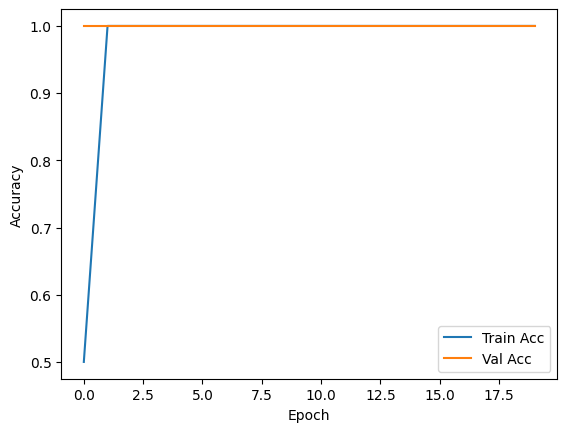

In [15]:
	plt.plot(history.history['accuracy'], label='Train Acc')
	plt.plot(history.history['val_accuracy'], label='Val Acc')
	plt.xlabel('Epoch')
	plt.ylabel('Accuracy')
	plt.legend()
	plt.show()

In [16]:
model.save('day_night_classifier_model.h5')